<a href="https://colab.research.google.com/github/Harshini-Bhandary21/AIML_LAB_PRACTICALS/blob/main/Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Name: Harshini Ramdas Bhandary

PRN:202401040151

Division :  A

Batch: A2

Roll : 35

**Title :  Performance Evaluation of Regression Model**


**Aim**: To implement and compare Simple Linear Regression, Multiple Linear Regression, Polynomial Regression, and Locally Weighted Linear Regression on a traffic accident dataset to predict the total number of injuries (injuries_total). The assignment also aims to understand Gradient Descent for parameter optimization, analyze error reduction and theta parameter changes through graphs, and evaluate model performance using Mean Squared Error (MSE) and Mean Absolute Error (MAE).

**Objectives of the Assignment**
1. To study and understand the fundamentals of regression analysis using a traffic accident dataset.
2. To perform data preprocessing, handle missing values, and prepare the dataset for regression modeling.
3. To implement Simple Linear Regression to analyze the relationship between a single input feature and total injuries.
4. To implement Multiple Linear Regression using multiple input features to predict total injuries.
5. To implement Polynomial Regression to capture nonlinear relationships between input features and the target variable.
6. To implement Locally Weighted Linear Regression (LWLR) to study local patterns in the data.
7. To understand and apply Gradient Descent for parameter optimization and observe how theta values change across iterations.
8. To visualize error reduction over iterations using loss curves and analyze parameter convergence using theta graphs.
9. To evaluate and compare regression models using Mean Squared Error (MSE) and Mean Absolute Error (MAE).
10. To identify the strengths and weaknesses of the implemented regression models and determine their predictive performance on test data.

THEORY

1. Introduction to Regression Analysis

Regression analysis is a supervised machine learning technique used to predict continuous numerical values based on one or more input variables. It identifies relationships between independent variables (features) and a dependent variable (target).

In this assignment, a traffic accident dataset is used to predict the total number of injuries (injuries_total) using features such as crash hour, number of units involved, crash month, and crash year. The performance of the models is evaluated using Mean Squared Error (MSE) and Mean Absolute Error (MAE).

2. Simple Linear Regression (SLR)

Simple Linear Regression models the relationship between one independent variable and one dependent variable using a straight line.

Equation:
y = b0 + b1x

Here, y is the predicted value, x is the independent variable, b0 is the intercept, and b1 is the slope or regression coefficient.

The model estimates the best-fit line by minimizing the squared differences between actual and predicted values.

Advantages: Simple to implement, fast, and easy to interpret.

Limitations: Uses only one feature and cannot capture complex nonlinear relationships.

3. Multiple Linear Regression (MLR)

Multiple Linear Regression uses two or more independent variables to predict a dependent variable.

Equation:
y = b0 + b1x1 + b2x2 + ... + bnxn

Here, b0 is the intercept, b1 to bn are regression coefficients, and x1 to xn are input features.

In this assignment, features such as crash hour, number of units, crash month, and crash year can be used to predict total injuries.

Advantages: Considers multiple factors simultaneously and may improve predictions when the features contain useful information.

Limitations: Assumes a linear relationship between the features and target and may be affected by irrelevant or highly correlated features.

4. Polynomial Regression

Polynomial Regression extends linear regression by including powers of input features to model curved relationships.

Equation for a second-degree polynomial:
y = b0 + b1x + b2x^2

Here, b0 is the intercept, b1 is the linear coefficient, b2 is the squared-term coefficient, and x is the independent variable.

In this assignment, the squared crash-hour feature allows the model to capture a curved relationship between crash hour and total injuries.

Advantages: Captures nonlinear patterns that a straight-line model may miss.

Limitations: Higher-degree polynomials can overfit the data and produce unrealistic predictions.

5. Locally Weighted Linear Regression (LWLR)

Locally Weighted Linear Regression is a non-parametric technique that fits a local regression model for each prediction. It assigns higher weights to nearby training observations and lower weights to distant observations.

Gaussian weight equation:
w_i = exp(-(x_i - x)^2 / (2 * tau^2))

Here, w_i is the weight assigned to a training observation, x_i is the training input, x is the input point being predicted, and tau is the bandwidth parameter.

Advantages: Captures local patterns and nonlinear relationships without requiring one global regression equation.

Limitations: Computationally expensive for large datasets and sensitive to the bandwidth parameter.

6. Gradient Descent

Gradient Descent is an optimization algorithm used to find model parameters that minimize a loss function. It repeatedly updates parameters in the direction that reduces prediction error.

Update equation:
theta_new = theta_old - alpha * gradient

Here, theta represents a model parameter, alpha is the learning rate, and the gradient indicates the direction and rate of change of the loss function.

During training, the model calculates predictions, measures errors, calculates gradients, and updates its parameters over multiple iterations.

Advantages: Supports iterative parameter optimization and helps explain how regression models learn.

Limitations: Performance depends on the learning rate, feature scaling, and number of iterations.

Gradient Descent Graphs:

Loss Curve: Shows how training error changes over iterations. A decreasing curve indicates that training error is reducing.

Theta vs Iterations: Shows how model parameters change during training. Parameters that stabilize may indicate convergence.

7. Evaluation Metrics

Mean Squared Error (MSE):

MSE measures the average squared difference between actual and predicted values.

MSE = (1/m) * sum((y_i - y_predicted_i)^2)

A lower MSE indicates smaller squared prediction errors. Large errors receive greater penalties because the differences are squared.

Mean Absolute Error (MAE):

MAE measures the average absolute difference between actual and predicted values.

MAE = (1/m) * sum(abs(y_i - y_predicted_i))

A lower MAE indicates that predictions are closer to actual values on average. MAE is expressed in the same units as the target variable.

8. Train-Test Split

The dataset is divided into two subsets.

Training Set: Used to train the regression model and learn its parameters.

Testing Set: Used to evaluate the model on observations not used during training.

This separation helps estimate how well a model generalizes to unseen data. Comparing test-set MSE and MAE provides a consistent way to assess predictive performance when models use the same test observations.

9. Conclusion

Regression analysis provides several methods for predicting numerical outcomes from data. Simple Linear Regression models a single-feature linear relationship, Multiple Linear Regression uses several features, Polynomial Regression captures curved relationships, and LWLR models local patterns. Gradient Descent provides an iterative approach to optimizing model parameters. By analyzing loss curves, theta values, MSE, and MAE, the strengths, limitations, and predictive performance of the implemented methods can be studied systematically.


*Flowchart:
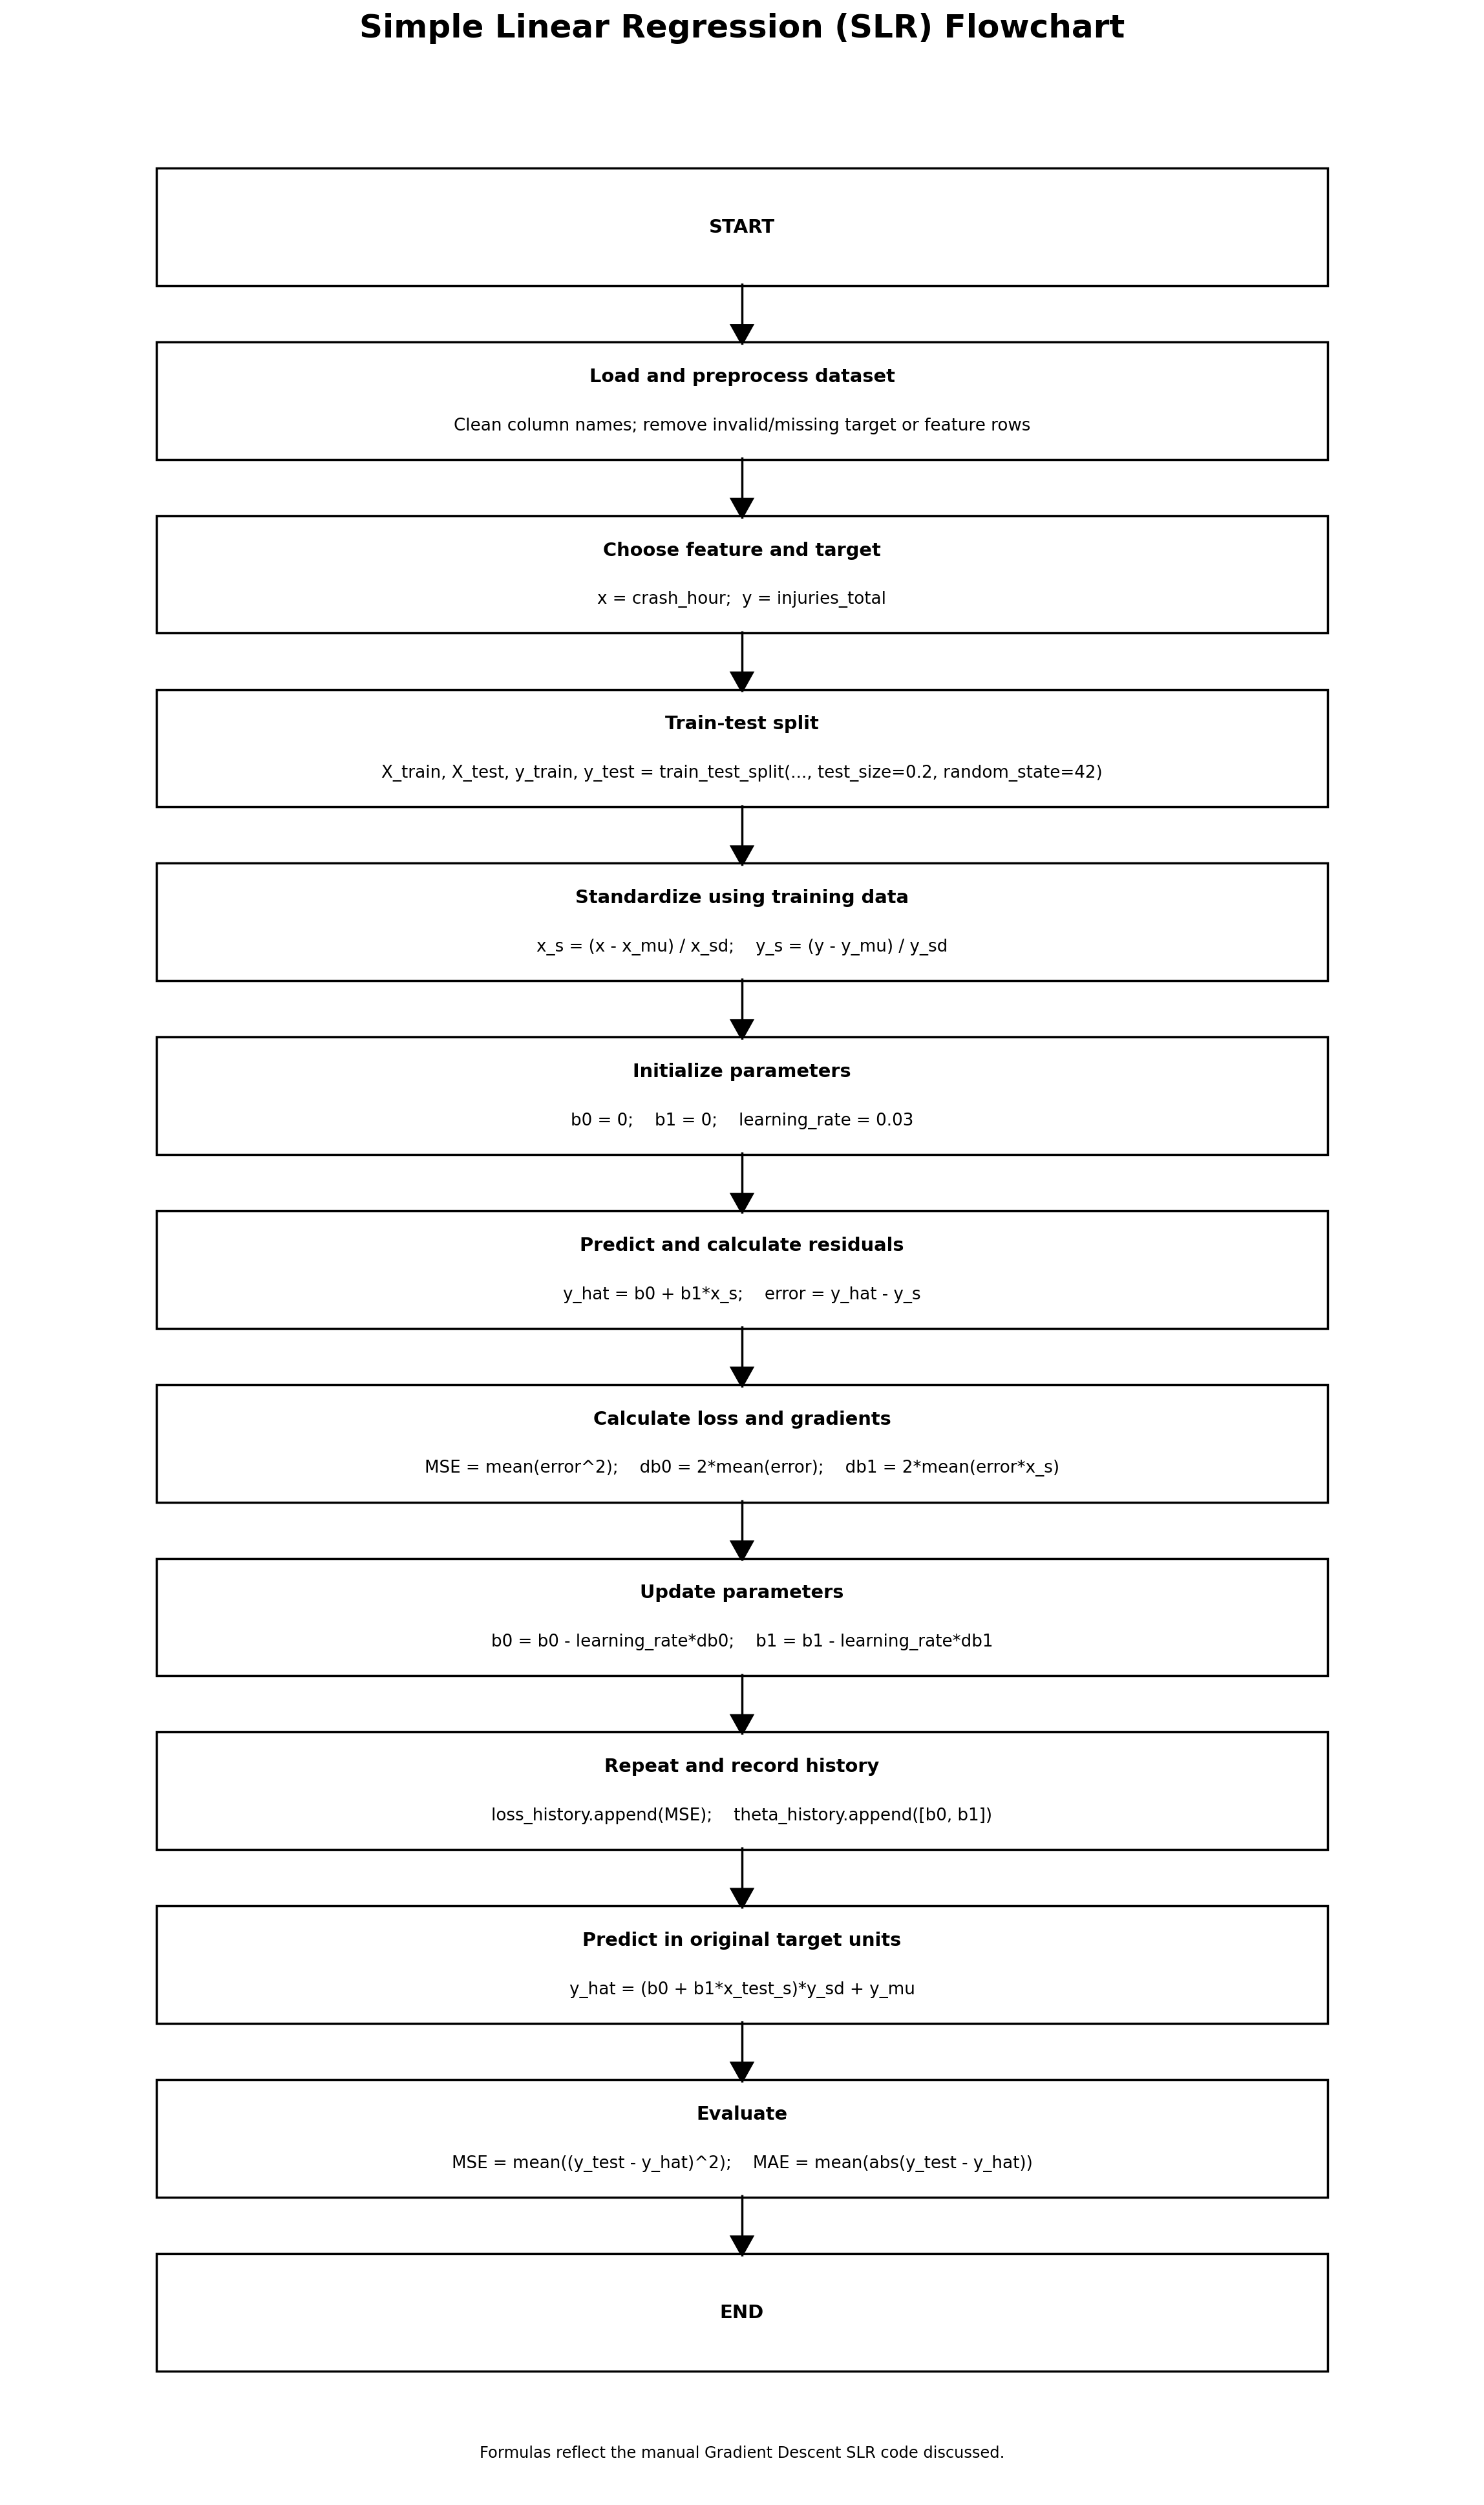



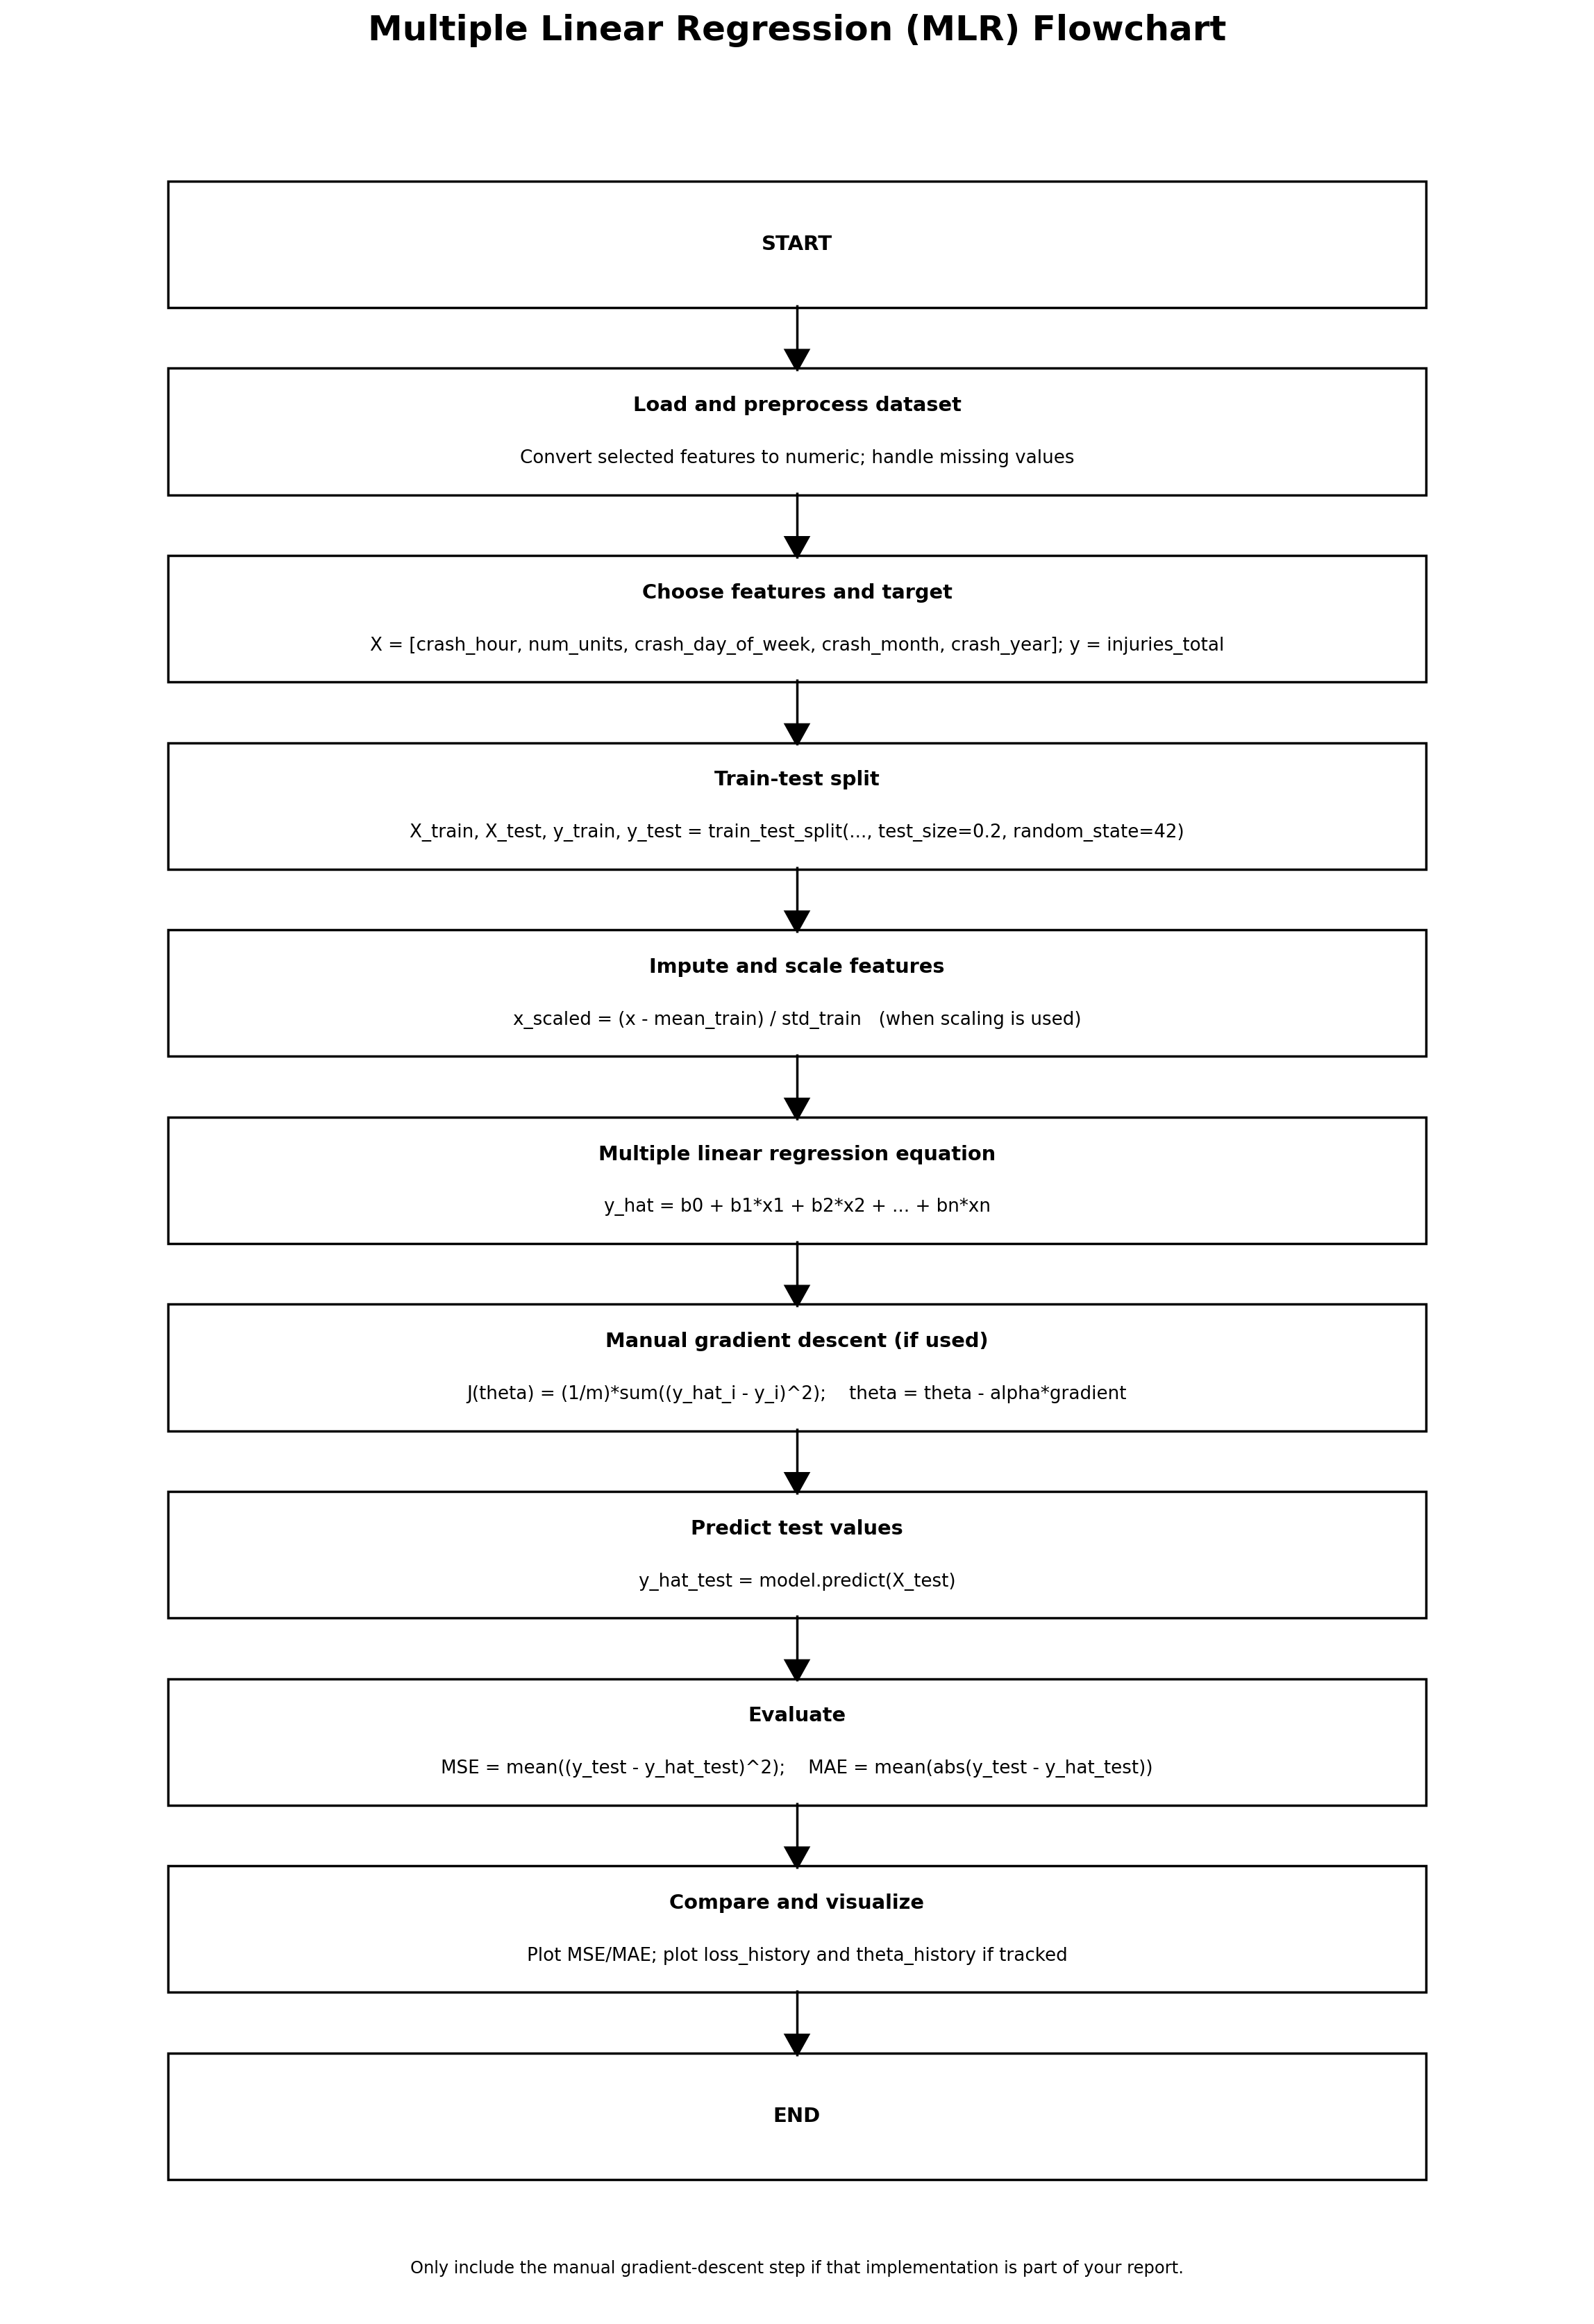


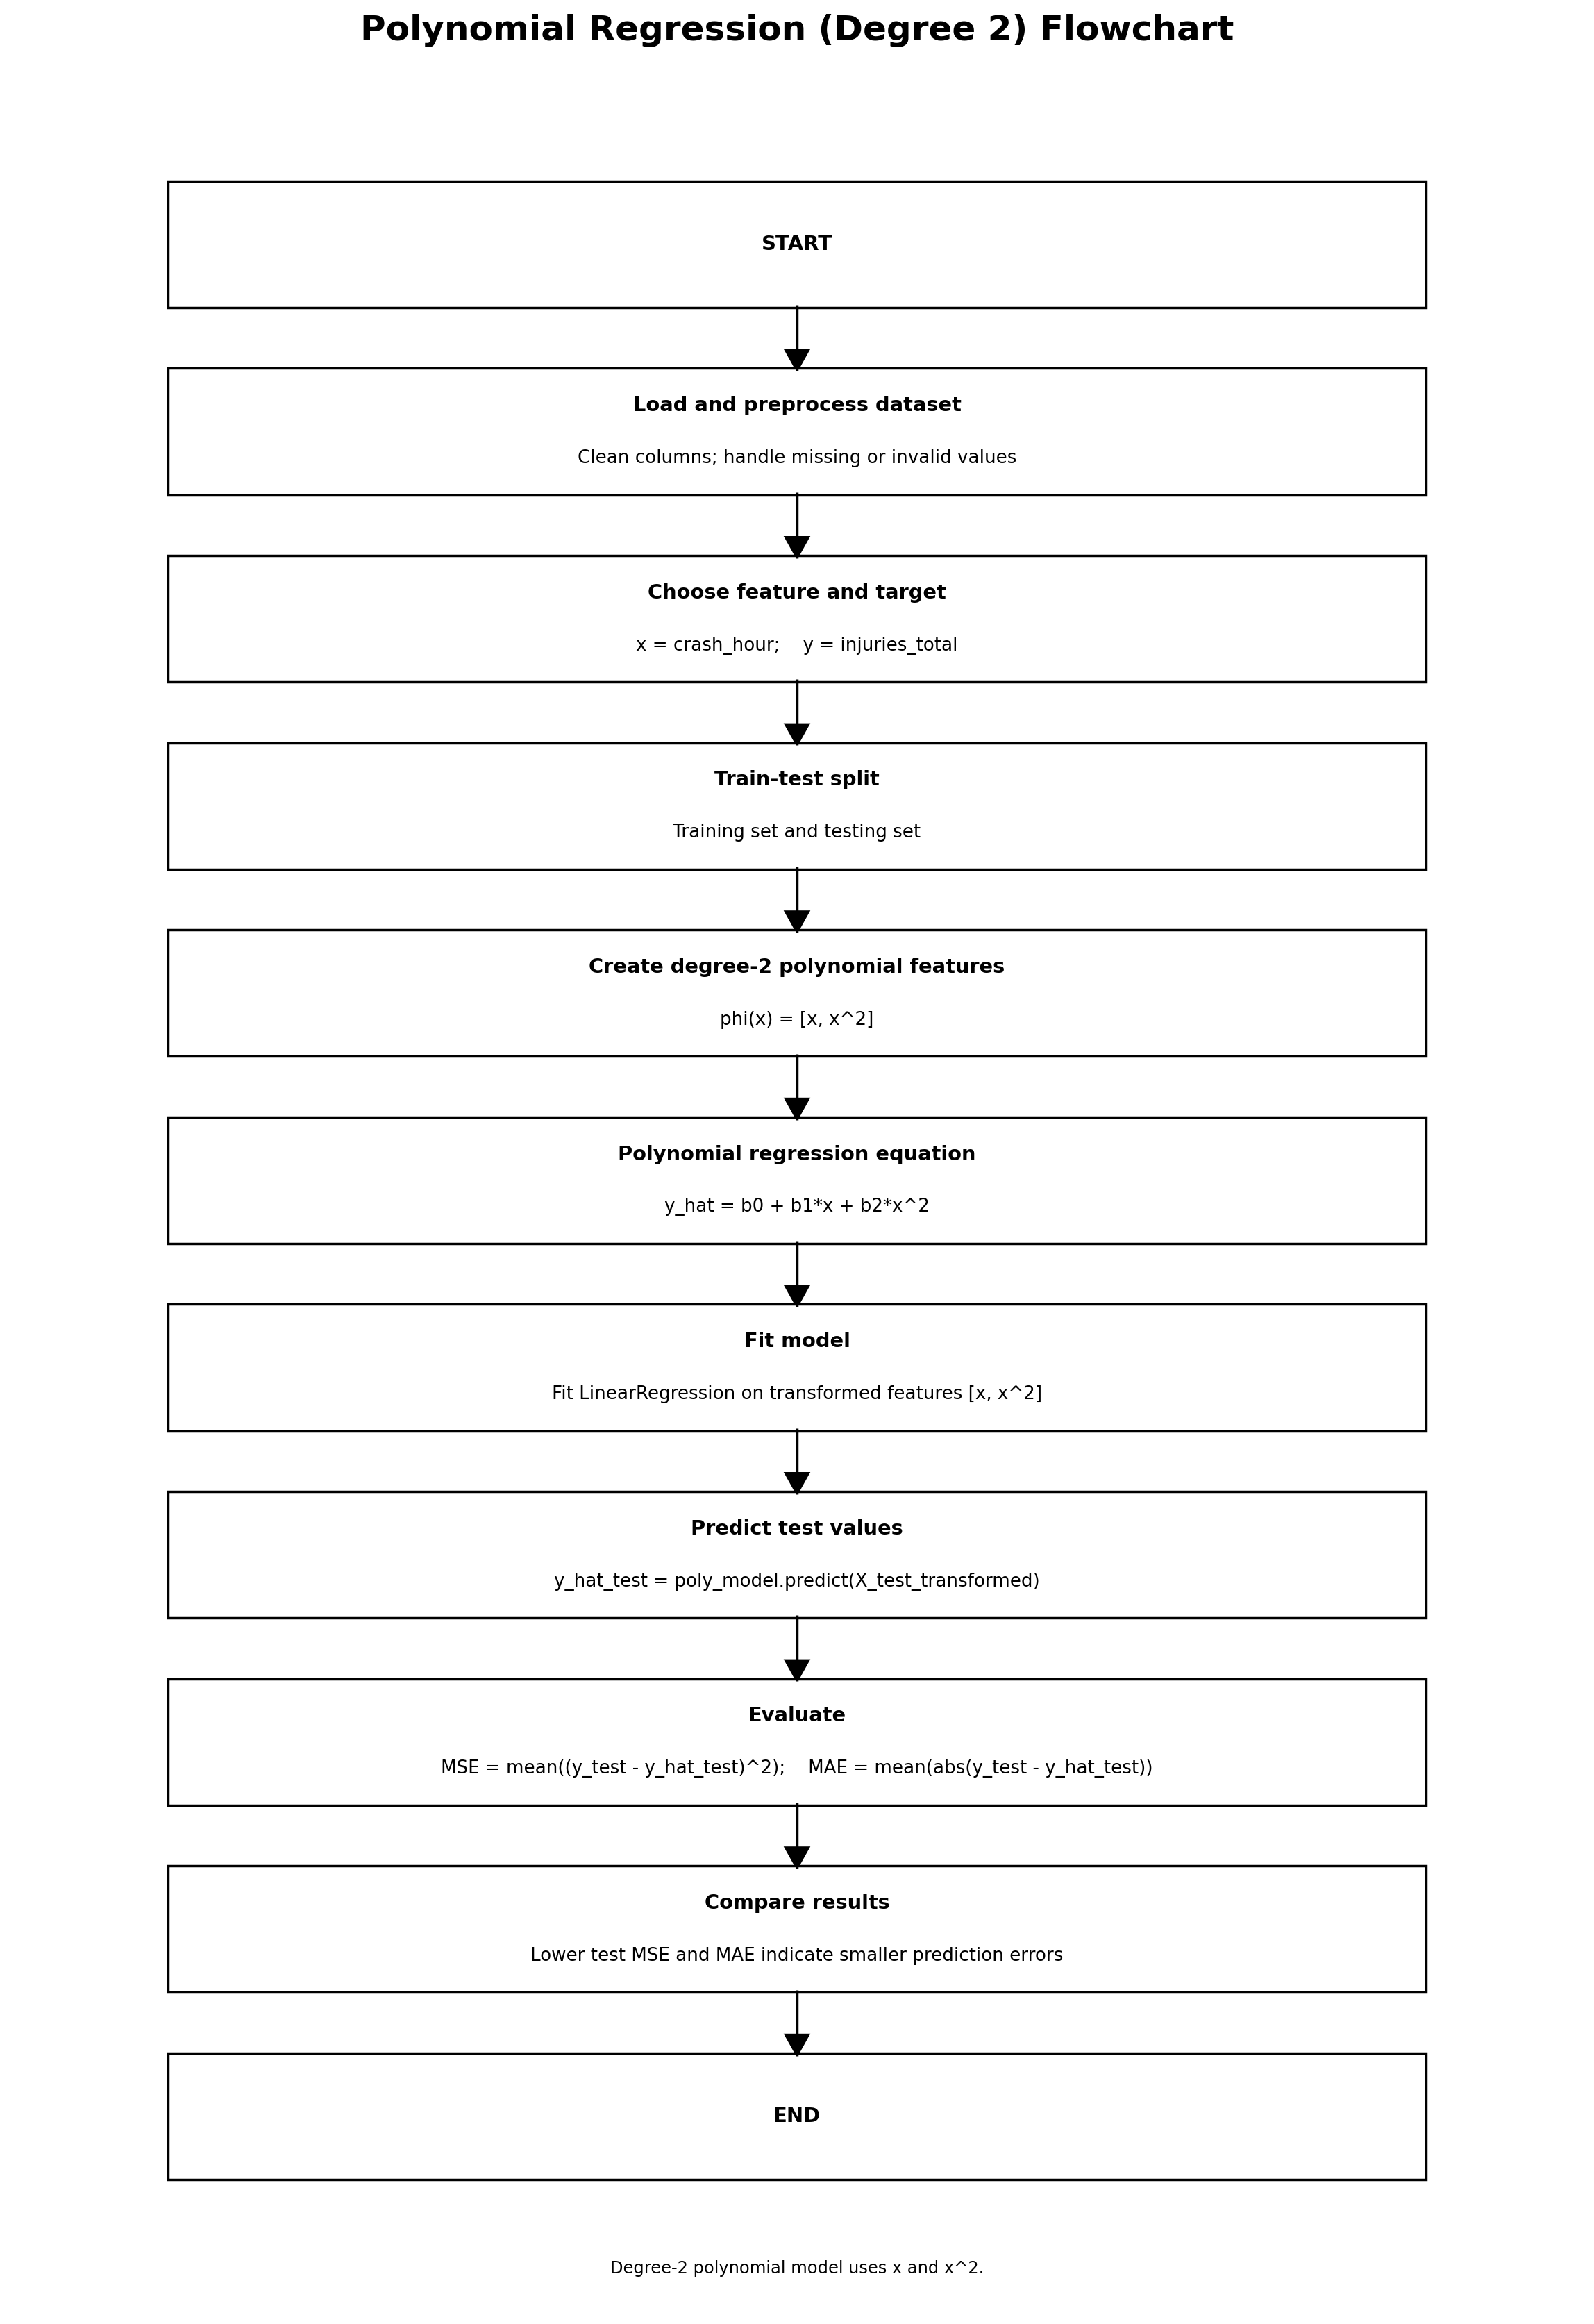



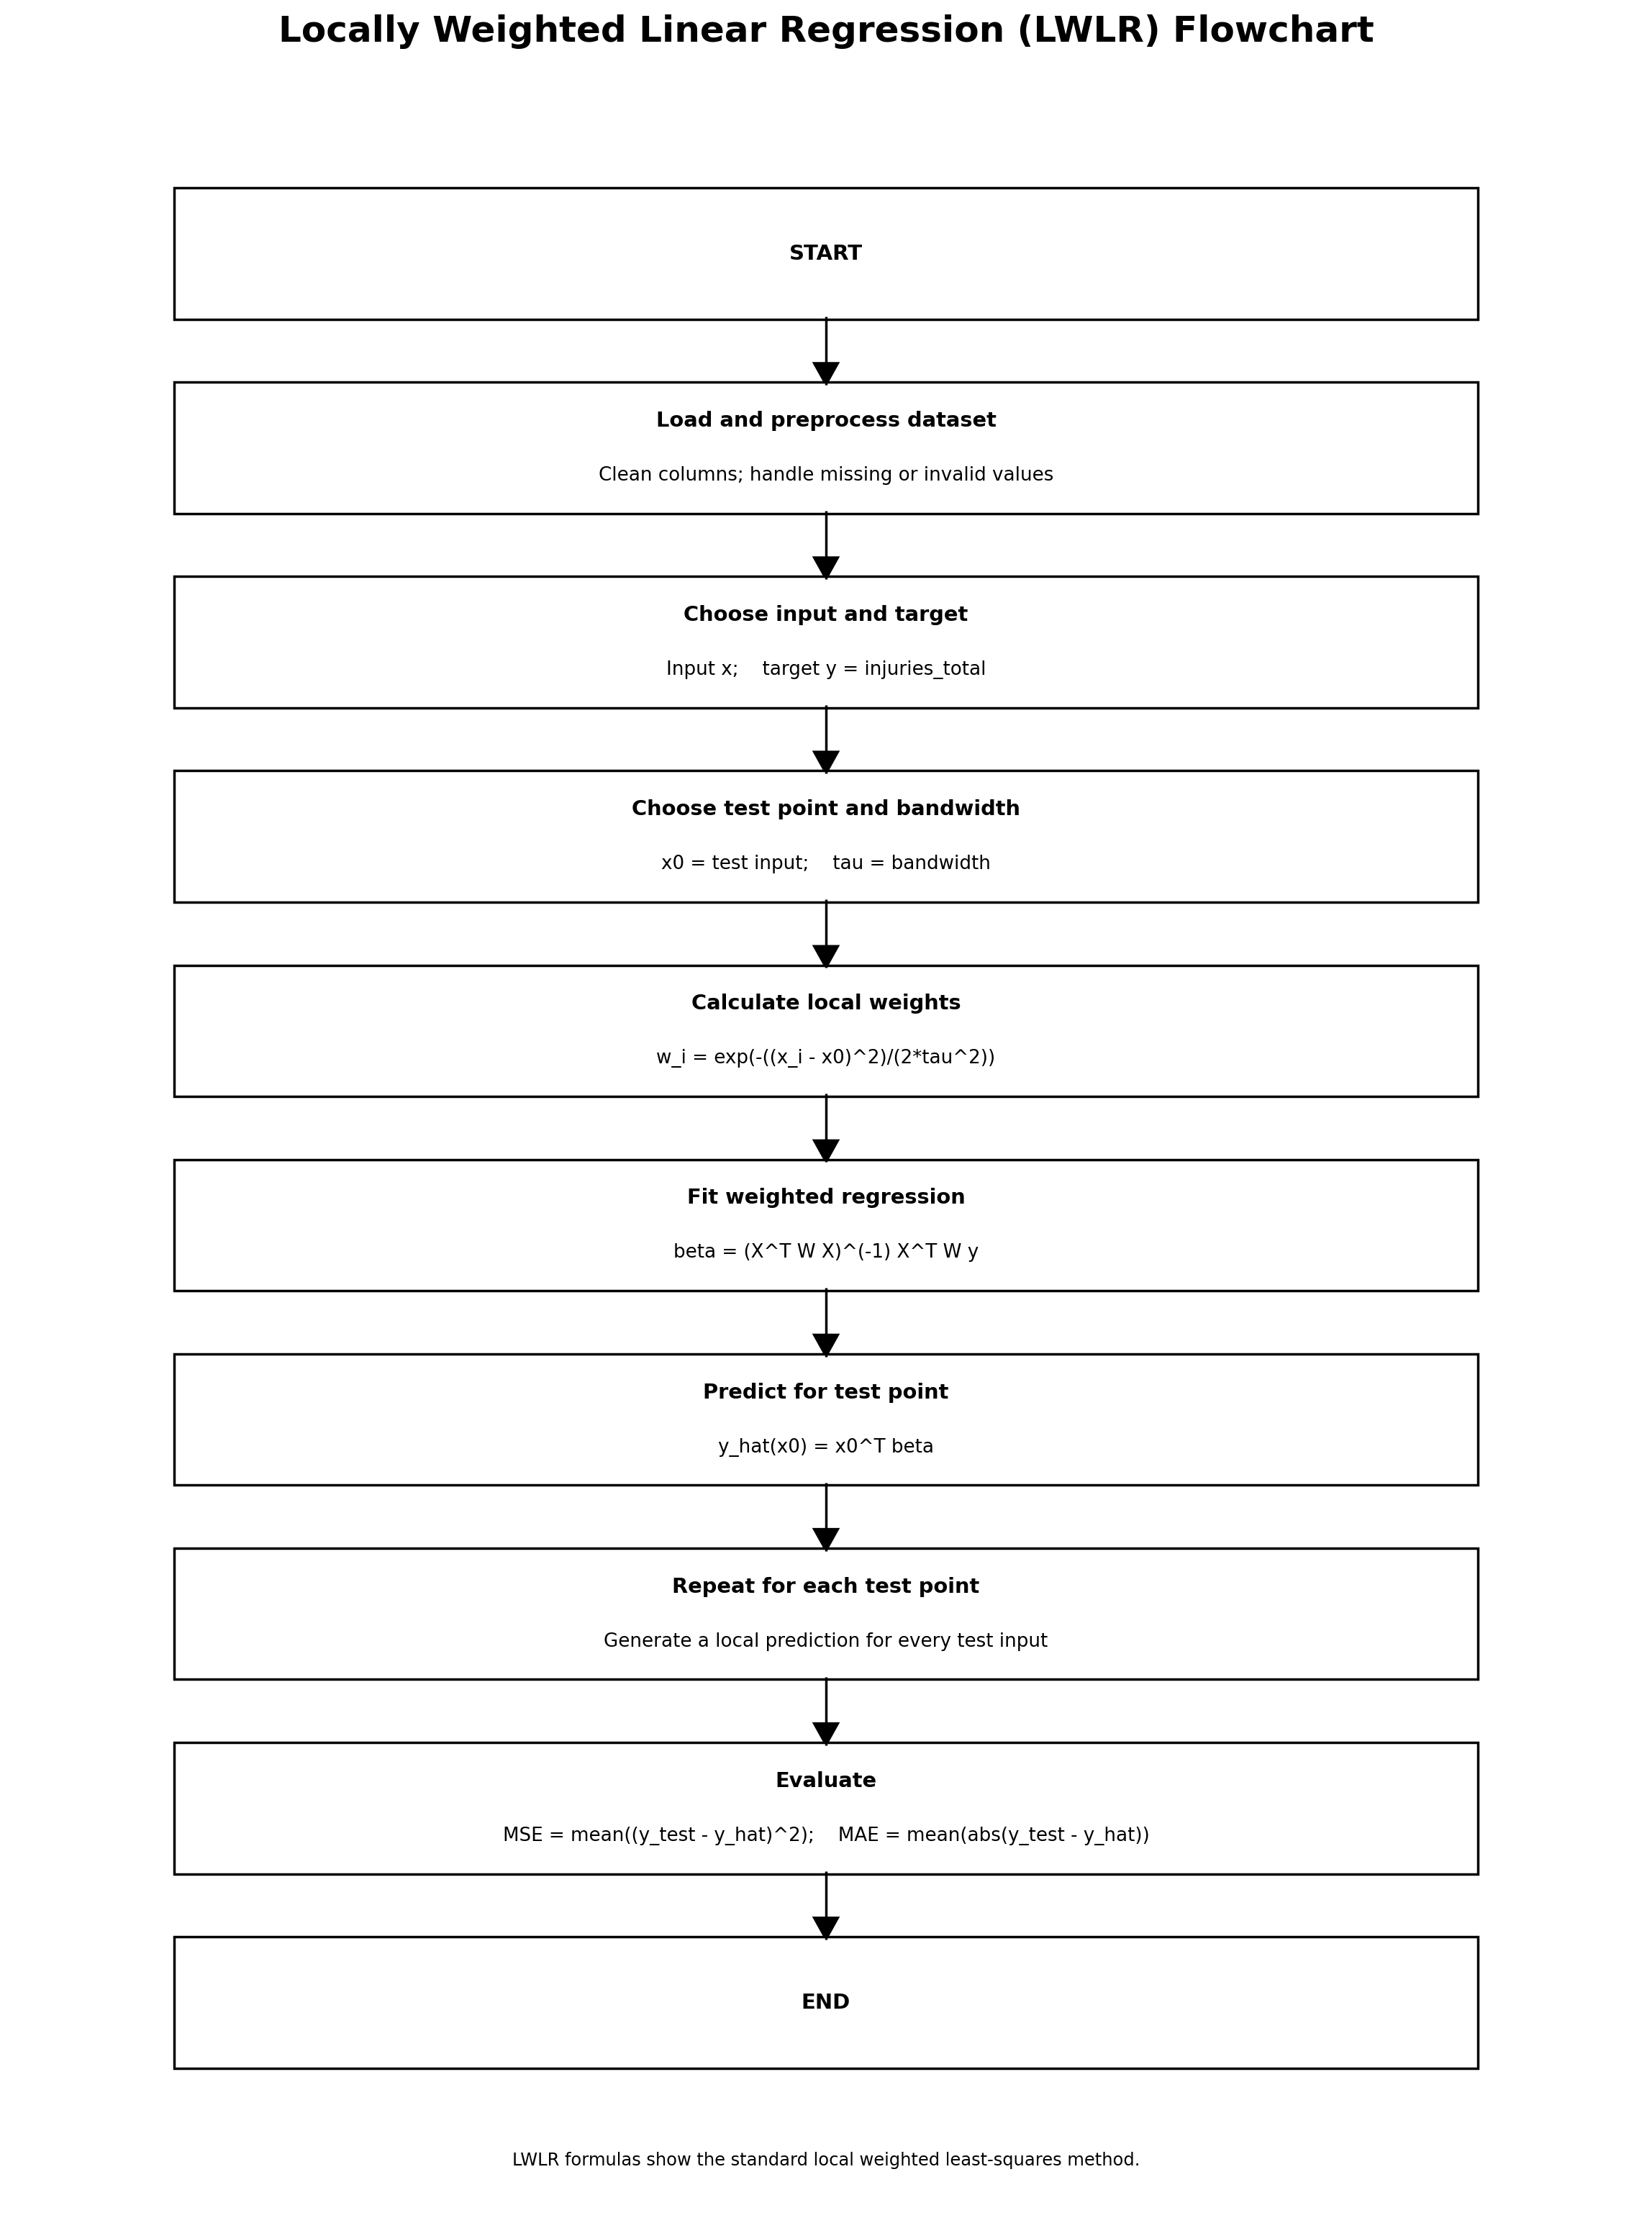


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

np.random.seed(42)

uploaded = files.upload()
file_name = next(iter(uploaded))

if file_name.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(file_name)
else:
    df = pd.read_csv(file_name)

df.columns = df.columns.str.strip().str.lower()

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


Saving traffic_accidents.csv to traffic_accidents (2).csv
Dataset shape: (209306, 24)
Columns: ['crash_date', 'traffic_control_device', 'weather_condition', 'lighting_condition', 'first_crash_type', 'trafficway_type', 'alignment', 'roadway_surface_cond', 'road_defect', 'crash_type', 'intersection_related_i', 'damage', 'prim_contributory_cause', 'num_units', 'most_severe_injury', 'injuries_total', 'injuries_fatal', 'injuries_incapacitating', 'injuries_non_incapacitating', 'injuries_reported_not_evident', 'injuries_no_indication', 'crash_hour', 'crash_day_of_week', 'crash_month']


,crash_date,traffic_control_device,weather_condition,lighting_condition,first_crash_type,trafficway_type,alignment,roadway_surface_cond,road_defect,crash_type,...,most_severe_injury,injuries_total,injuries_fatal,injuries_incapacitating,injuries_non_incapacitating,injuries_reported_not_evident,injuries_no_indication,crash_hour,crash_day_of_week,crash_month
0,07/29/2023 01:00:00 PM,TRAFFIC SIGNAL,CLEAR,DAYLIGHT,TURNING,NOT DIVIDED,STRAIGHT AND LEVEL,UNKNOWN,UNKNOWN,NO INJURY / DRIVE AWAY,...,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,3.0,13,7,7
1,08/13/2023 12:11:00 AM,TRAFFIC SIGNAL,CLEAR,"DARKNESS, LIGHTED ROAD",TURNING,FOUR WAY,STRAIGHT AND LEVEL,DRY,NO DEFECTS,NO INJURY / DRIVE AWAY,...,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,2.0,0,1,8
2,12/09/2021 10:30:00 AM,TRAFFIC SIGNAL,CLEAR,DAYLIGHT,REAR END,T-INTERSECTION,STRAIGHT AND LEVEL,DRY,NO DEFECTS,NO INJURY / DRIVE AWAY,...,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,3.0,10,5,12
3,08/09/2023 07:55:00 PM,TRAFFIC SIGNAL,CLEAR,DAYLIGHT,ANGLE,FOUR WAY,STRAIGHT AND LEVEL,DRY,NO DEFECTS,INJURY AND / OR TOW DUE TO CRASH,...,NONINCAPACITATING INJURY,5.0,0.0,0.0,5.0,0.0,0.0,19,4,8
4,08/19/2023 02:55:00 PM,TRAFFIC SIGNAL,CLEAR,DAYLIGHT,REAR END,T-INTERSECTION,STRAIGHT AND LEVEL,UNKNOWN,UNKNOWN,NO INJURY / DRIVE AWAY,...,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,3.0,14,7,8


In [ ]:

TARGET = "injuries_total"
FEATURE = "crash_hour"

if TARGET not in df.columns:
    raise ValueError(f"Missing target column: {TARGET}")

if FEATURE not in df.columns:
    raise ValueError(f"Missing predictor column: {FEATURE}")

data = df.drop_duplicates().copy()

data[TARGET] = pd.to_numeric(data[TARGET], errors="coerce")
data[FEATURE] = pd.to_numeric(data[FEATURE], errors="coerce")

data = data.dropna(subset=[TARGET, FEATURE])
data = data[np.isfinite(data[TARGET]) & np.isfinite(data[FEATURE])]
data = data[data[TARGET] >= 0].copy()

# Simple regression data
X_simple = data[[FEATURE]].to_numpy(dtype=float)
y_simple = data[TARGET].to_numpy(dtype=float)

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y_simple, test_size=0.2, random_state=42
)

print("Rows:", len(data))
print("Simple regression predictor:", FEATURE)
print("Target:", TARGET)
print("Training rows:", len(X_train_s))
print("Testing rows:", len(X_test_s))


Rows: 209275
Simple regression predictor: crash_hour
Target: injuries_total
Training rows: 167420
Testing rows: 41855


SIMPLE LINEAR REGRESSION
Intercept: 0.4105271047478567
Slope: -0.002235375640731531
MSE: 0.6478447170333245
MAE: 0.5693365032012935


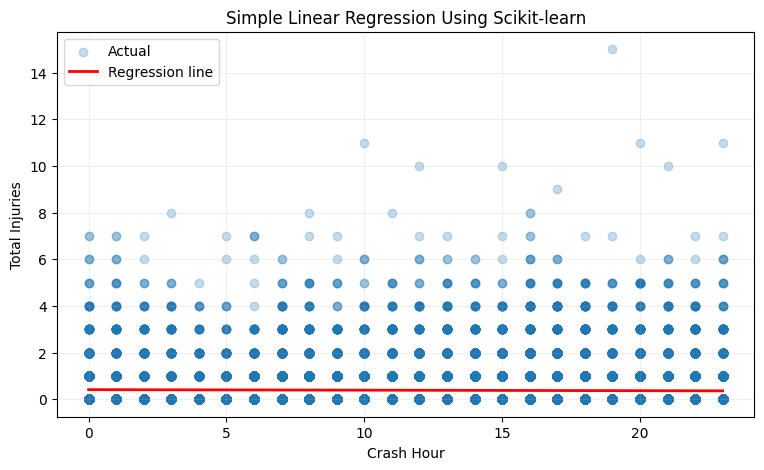

In [ ]:

# Train model
linear_model = LinearRegression()
linear_model.fit(X_train_s, y_train_s)

# Predict
pred_linear = linear_model.predict(X_test_s)

print("SIMPLE LINEAR REGRESSION")
print("Intercept:", linear_model.intercept_)
print("Slope:", linear_model.coef_[0])
print("MSE:", mean_squared_error(y_test_s, pred_linear))
print("MAE:", mean_absolute_error(y_test_s, pred_linear))

# Plot regression line
order = np.argsort(X_test_s[:, 0])

plt.figure(figsize=(9, 5))
plt.scatter(X_test_s[:, 0], y_test_s, alpha=0.25, label="Actual")
plt.plot(
    X_test_s[order, 0],
    pred_linear[order],
    color="red",
    linewidth=2,
    label="Regression line"
)
plt.xlabel("Crash Hour")
plt.ylabel("Total Injuries")
plt.title("Simple Linear Regression Using Scikit-learn")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


In [ ]:

# With libraries
print("Simple Linear Regression")
print("MSE:", mean_squared_error(y_test_s, pred_linear))
print("MAE:", mean_absolute_error(y_test_s, pred_linear))

# Without metric libraries
errors = y_test_s - pred_manual_linear

mse_manual = np.mean(errors ** 2)
mae_manual = np.mean(np.abs(errors))

print("\nSimple Linear Regression (Manual)")
print("MSE:", mse_manual)
print("MAE:", mae_manual)


Simple Linear Regression
MSE: 0.6478447170333245
MAE: 0.5693365032012935

Simple Linear Regression (Manual)
MSE: 0.6478447170333245
MAE: 0.5693365032012933


Simple Linear Regression Comparison


,Method,MSE,MAE
0,With Library,0.647845,0.569337
1,Without Library,0.647845,0.569337


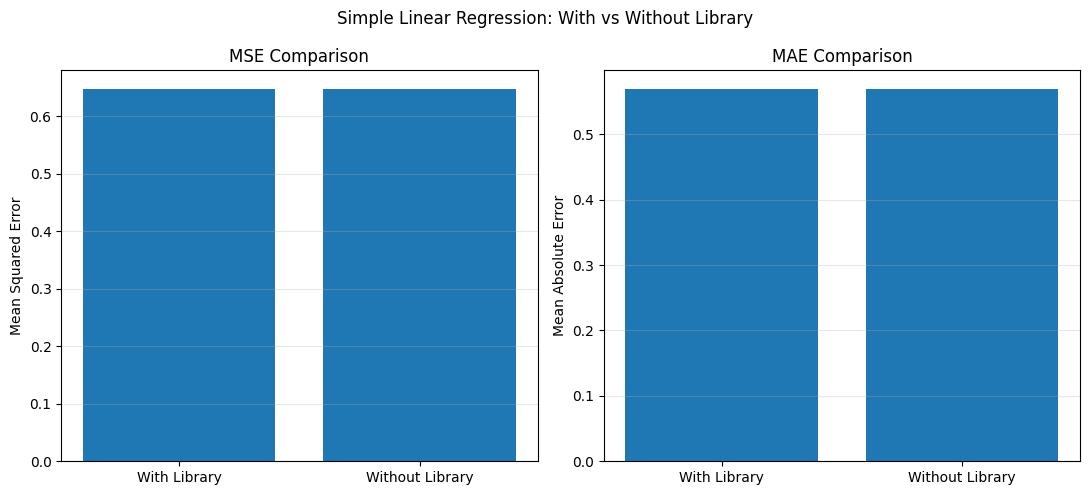

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Predictions
pred_library = linear_model.predict(X_test_s)
pred_without_library = pred_manual_linear

# Calculate MSE and MAE
comparison = pd.DataFrame({
    "Method": ["With Library", "Without Library"],
    "MSE": [
        np.mean((y_test_s - pred_library) ** 2),
        np.mean((y_test_s - pred_without_library) ** 2)
    ],
    "MAE": [
        np.mean(np.abs(y_test_s - pred_library)),
        np.mean(np.abs(y_test_s - pred_without_library))
    ]
})

print("Simple Linear Regression Comparison")
display(comparison.round(6))

# Bar graphs
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].bar(comparison["Method"], comparison["MSE"])
axes[0].set_title("MSE Comparison")
axes[0].set_ylabel("Mean Squared Error")

axes[1].bar(comparison["Method"], comparison["MAE"])
axes[1].set_title("MAE Comparison")
axes[1].set_ylabel("Mean Absolute Error")

for ax in axes:
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Simple Linear Regression: With vs Without Library")
plt.tight_layout()
plt.show()


SIMPLE LINEAR REGRESSION FROM SCRATCH
Intercept: 0.41052710474785675
Slope: -0.0022353756407315333
MSE: 0.6478447170333245
MAE: 0.5693365032012933


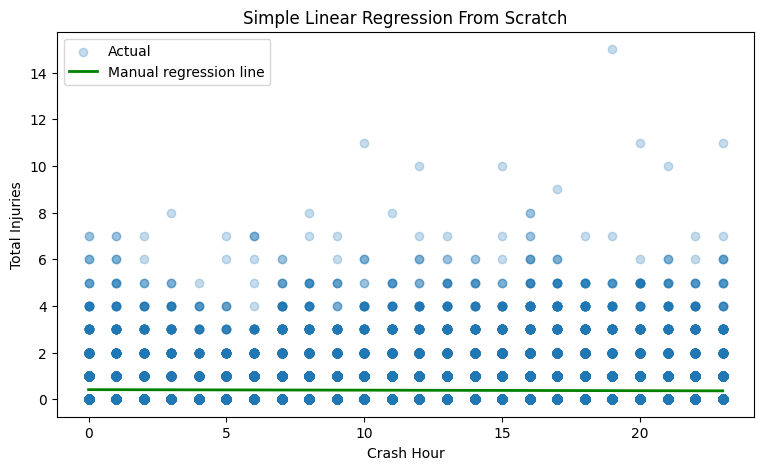

In [ ]:

x_train = X_train_s[:, 0]
x_test = X_test_s[:, 0]

x_mean = np.mean(x_train)
y_mean = np.mean(y_train_s)

slope_manual = (
    np.sum((x_train - x_mean) * (y_train_s - y_mean))
    / np.sum((x_train - x_mean) ** 2)
)

intercept_manual = y_mean - slope_manual * x_mean

pred_manual_linear = intercept_manual + slope_manual * x_test

print("SIMPLE LINEAR REGRESSION FROM SCRATCH")
print("Intercept:", intercept_manual)
print("Slope:", slope_manual)
print("MSE:", np.mean((y_test_s - pred_manual_linear) ** 2))
print("MAE:", np.mean(np.abs(y_test_s - pred_manual_linear)))


# Plot
order = np.argsort(x_test)

plt.figure(figsize=(9, 5))
plt.scatter(x_test, y_test_s, alpha=0.25, label="Actual")
plt.plot(
    x_test[order],
    pred_manual_linear[order],
    color="green",
    linewidth=2,
    label="Manual regression line"
)
plt.xlabel("Crash Hour")
plt.ylabel("Total Injuries")
plt.title("Simple Linear Regression From Scratch")
plt.legend()
plt.show()


GRADIENT DESCENT RESULTS
MSE: 0.6478447170333245
MAE: 0.5693365032012933
Final theta 0 (intercept): 1.1240003472625825e-17
Final theta 1 (slope): -0.015684511808472117


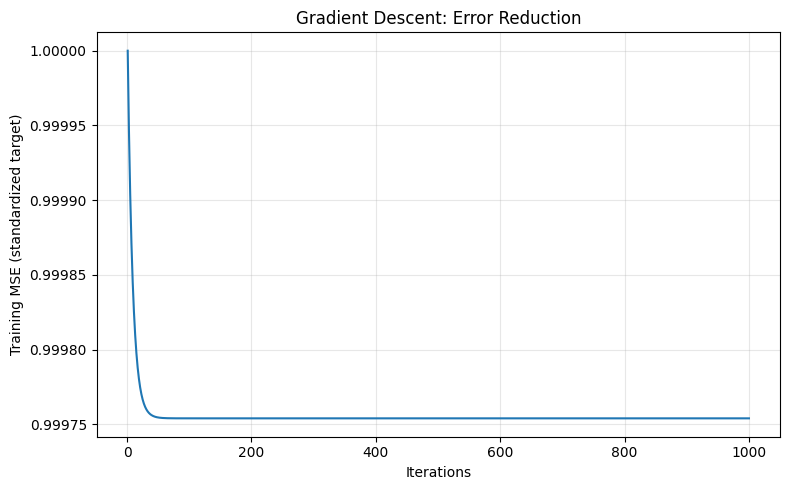

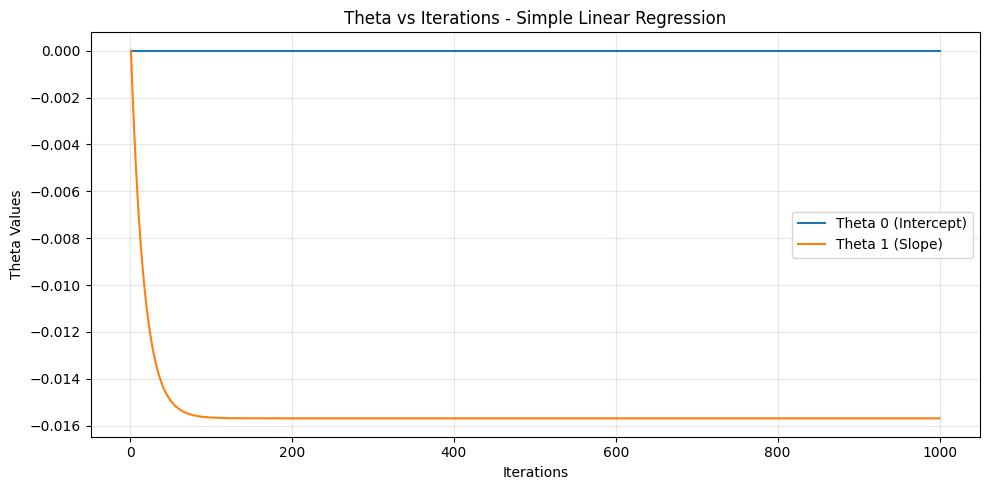

In [ ]:


# Standardize using training data only
x_mu, x_sd = x_train.mean(), x_train.std()
y_mu, y_sd = y_train_s.mean(), y_train_s.std()

if x_sd == 0:
    x_sd = 1.0
if y_sd == 0:
    y_sd = 1.0

xs = (x_train - x_mu) / x_sd
ys = (y_train_s - y_mu) / y_sd
x_test_scaled = (x_test - x_mu) / x_sd

# Initialize parameters
b0_gd = 0.0
b1_gd = 0.0

learning_rate = 0.03
epochs = 1000

loss_history = []
theta_history = []

# Gradient descent training
for epoch in range(epochs):
    predictions = b0_gd + b1_gd * xs
    error = predictions - ys

    loss = np.mean(error ** 2)
    loss_history.append(loss)

    # Save current parameter values
    theta_history.append([b0_gd, b1_gd])

    # Calculate gradients
    db0 = 2 * np.mean(error)
    db1 = 2 * np.mean(error * xs)

    # Update parameters
    b0_gd -= learning_rate * db0
    b1_gd -= learning_rate * db1

# Convert history to NumPy array
theta_history_array = np.array(theta_history)

# Predict on test data
pred_gd_scaled = b0_gd + b1_gd * x_test_scaled
pred_gd = pred_gd_scaled * y_sd + y_mu

# Evaluation
print("GRADIENT DESCENT RESULTS")
print("MSE:", mean_squared_error(y_test_s, pred_gd))
print("MAE:", mean_absolute_error(y_test_s, pred_gd))
print("Final theta 0 (intercept):", b0_gd)
print("Final theta 1 (slope):", b1_gd)

# Graph 1: Error reduction over iterations
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), loss_history)
plt.xlabel("Iterations")
plt.ylabel("Training MSE (standardized target)")
plt.title("Gradient Descent: Error Reduction")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 2: Theta vs iterations
plt.figure(figsize=(10, 5))
plt.plot(
    range(1, epochs + 1),
    theta_history_array[:, 0],
    label="Theta 0 (Intercept)"
)
plt.plot(
    range(1, epochs + 1),
    theta_history_array[:, 1],
    label="Theta 1 (Slope)"
)
plt.xlabel("Iterations")
plt.ylabel("Theta Values")
plt.title("Theta vs Iterations - Simple Linear Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


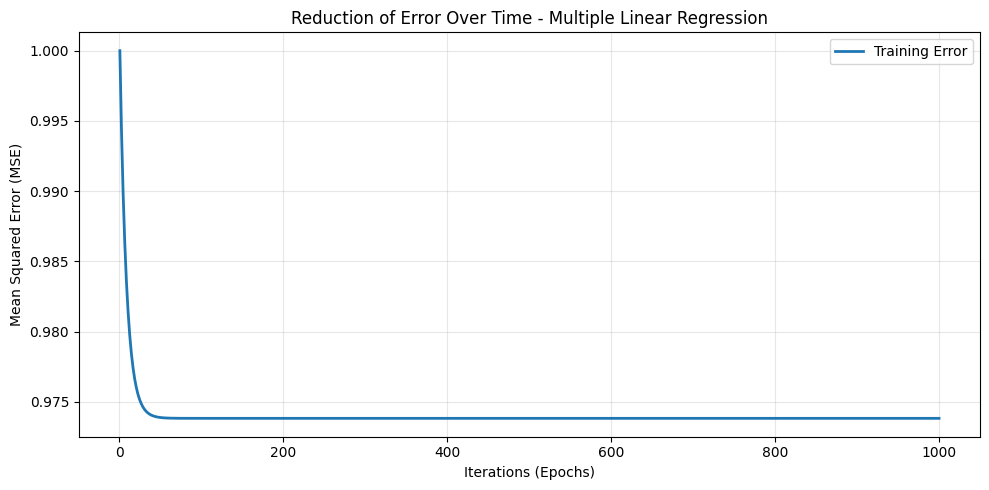

In [ ]:

import matplotlib.pyplot as plt

# Plot error reduction over iterations
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(loss_multi_history) + 1),
    loss_multi_history,
    label="Training Error",
    linewidth=2
)

plt.xlabel("Iterations (Epochs)")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Reduction of Error Over Time - Multiple Linear Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


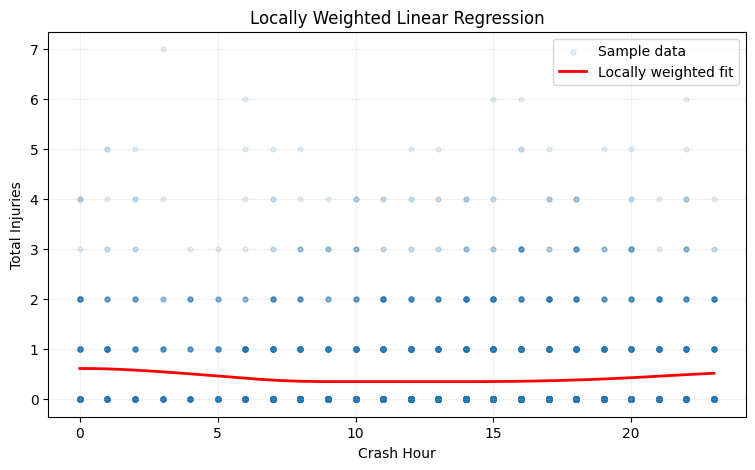

In [ ]:

def locally_weighted_regression(X_train, y_train, X_query, tau=2.0):
    """
    X_train and X_query should contain one numerical feature.
    tau controls the width of the local neighborhood.
    """
    X_train = np.asarray(X_train).reshape(-1)
    y_train = np.asarray(y_train).reshape(-1)
    X_query = np.asarray(X_query).reshape(-1)

    predictions = []

    for x0 in X_query:
        weights = np.exp(
            -((X_train - x0) ** 2) / (2 * tau ** 2)
        )

        # Weighted least squares for intercept and slope
        design = np.column_stack([
            np.ones(len(X_train)), X_train
        ])

        weighted_design = design * np.sqrt(weights)[:, None]
        weighted_y = y_train * np.sqrt(weights)

        beta = np.linalg.lstsq(
            weighted_design, weighted_y, rcond=None
        )[0]

        predictions.append(beta[0] + beta[1] * x0)

    return np.array(predictions)


# Subsample training data to make LWLR faster
rng = np.random.default_rng(42)
sample_size = min(5000, len(x_train))
indices = rng.choice(len(x_train), sample_size, replace=False)

x_lw = x_train[indices]
y_lw = y_train_s[indices]

x_grid = np.linspace(x_lw.min(), x_lw.max(), 150)
y_grid = locally_weighted_regression(
    x_lw, y_lw, x_grid, tau=2.0
)

plt.figure(figsize=(9, 5))
plt.scatter(x_lw, y_lw, alpha=0.12, s=12, label="Sample data")
plt.plot(
    x_grid, y_grid,
    color="red", linewidth=2,
    label="Locally weighted fit"
)
plt.xlabel("Crash Hour")
plt.ylabel("Total Injuries")
plt.title("Locally Weighted Linear Regression")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


In [ ]:

# Select numerical predictors available in the dataset
preferred_features = [
    "crash_hour",
    "num_units",
    "crash_day_of_week",
    "crash_month",
    "crash_year"
]

multiple_features = [
    col for col in preferred_features
    if col in data.columns and col != TARGET
]

if len(multiple_features) < 2:
    raise ValueError(
        "At least two numerical predictors are required. "
        f"Available columns: {data.columns.tolist()}"
    )

multi_data = data[multiple_features + [TARGET]].copy()

for col in multiple_features:
    multi_data[col] = pd.to_numeric(
        multi_data[col], errors="coerce"
    )

multi_data[TARGET] = pd.to_numeric(
    multi_data[TARGET], errors="coerce"
)

multi_data = multi_data.replace([np.inf, -np.inf], np.nan)
multi_data = multi_data.dropna(subset=[TARGET])
multi_data = multi_data.dropna(axis=1, how="all")

multiple_features = [
    col for col in multiple_features
    if col in multi_data.columns
]

X_multi = multi_data[multiple_features]
y_multi = multi_data[TARGET]

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y_multi,
    test_size=0.2,
    random_state=42
)

print("Multiple regression features:", multiple_features)
print("Training rows:", len(X_train_m))
print("Testing rows:", len(X_test_m))


Multiple regression features: ['crash_hour', 'num_units', 'crash_day_of_week', 'crash_month']
Training rows: 167420
Testing rows: 41855


MULTIPLE LINEAR REGRESSION: SCIKIT-LEARN
MSE: 0.6307596838137852
MAE: 0.5577883589457442


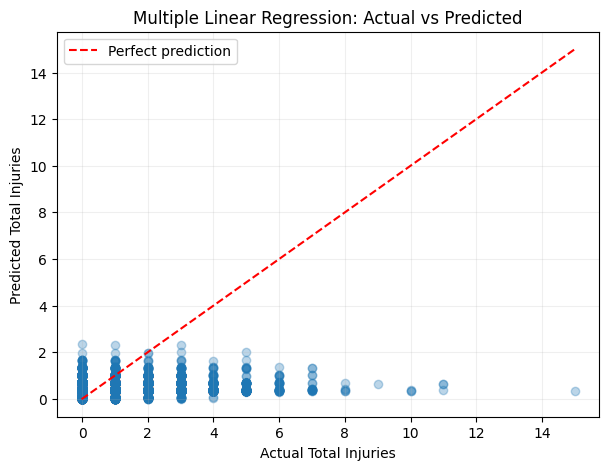

Intercept (standardized features): 0.38062358141201774
Coefficients:


,Feature,Coefficient
0,crash_hour,-0.013659
1,num_units,0.127673
2,crash_day_of_week,-0.010545
3,crash_month,0.010831


In [ ]:

# Impute missing predictors and fit the model
multiple_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LinearRegression()
)

multiple_model.fit(X_train_m, y_train_m)
pred_multiple = multiple_model.predict(X_test_m)

print("MULTIPLE LINEAR REGRESSION: SCIKIT-LEARN")
print("MSE:", mean_squared_error(y_test_m, pred_multiple))
print("MAE:", mean_absolute_error(y_test_m, pred_multiple))

# Actual vs predicted graph
plt.figure(figsize=(7, 5))
plt.scatter(y_test_m, pred_multiple, alpha=0.3)

low = min(y_test_m.min(), pred_multiple.min())
high = max(y_test_m.max(), pred_multiple.max())
plt.plot([low, high], [low, high], "r--", label="Perfect prediction")

plt.xlabel("Actual Total Injuries")
plt.ylabel("Predicted Total Injuries")
plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# Display model coefficients
fitted_lr = multiple_model.named_steps["linearregression"]
print("Intercept (standardized features):", fitted_lr.intercept_)
print("Coefficients:")
display(pd.DataFrame({
    "Feature": multiple_features,
    "Coefficient": fitted_lr.coef_
}))


In [ ]:

# With sklearn metric functions
mse_lib_multi = mean_squared_error(y_test_m, pred_multiple)
mae_lib_multi = mean_absolute_error(y_test_m, pred_multiple)

# Manual calculations using NumPy
error_multi = y_test_m.to_numpy() - pred_multiple

mse_manual_multi = np.mean(error_multi ** 2)
mae_manual_multi = np.mean(np.abs(error_multi))

print("MULTIPLE REGRESSION ERROR COMPARISON")
print(f"MSE with library:    {mse_lib_multi:.6f}")
print(f"MSE without library: {mse_manual_multi:.6f}")
print(f"MAE with library:    {mae_lib_multi:.6f}")
print(f"MAE without library: {mae_manual_multi:.6f}")


MULTIPLE REGRESSION ERROR COMPARISON
MSE with library:    0.630760
MSE without library: 0.630760
MAE with library:    0.557788
MAE without library: 0.557788


Multiple Linear Regression Comparison


,Method,MSE,MAE
0,With Library,0.63076,0.557788
1,Without Library,0.63076,0.557788


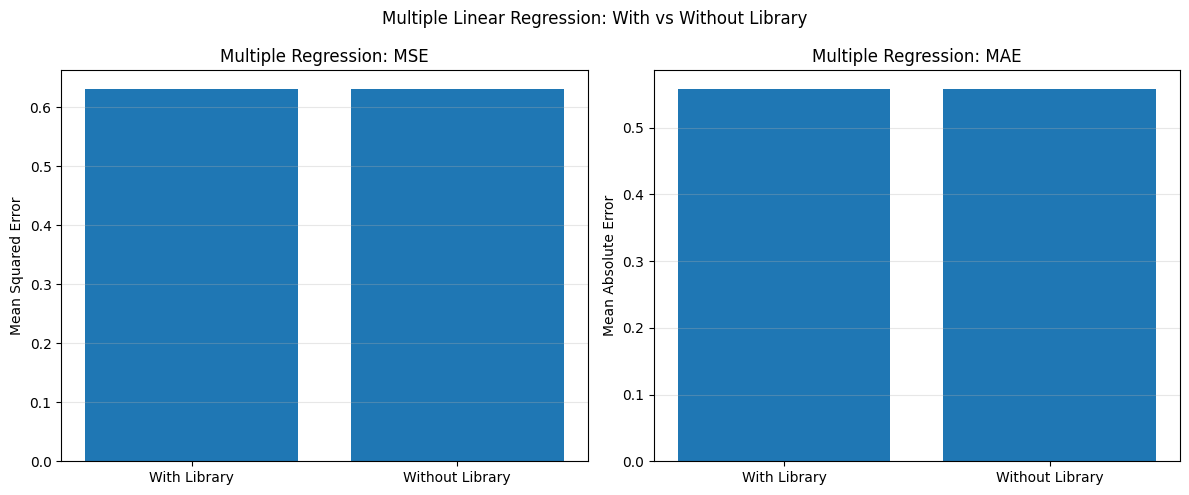

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Predictions using library
pred_library_multi = multiple_model.predict(X_test_m)

# Predictions without library (manual gradient descent)
pred_without_library_multi = pred_multi_scratch

# Calculate MSE and MAE
comparison_multi = pd.DataFrame({
    "Method": ["With Library", "Without Library"],
    "MSE": [
        np.mean((np.asarray(y_test_m) - pred_library_multi) ** 2),
        np.mean((np.asarray(y_test_m) - pred_without_library_multi) ** 2)
    ],
    "MAE": [
        np.mean(np.abs(np.asarray(y_test_m) - pred_library_multi)),
        np.mean(np.abs(np.asarray(y_test_m) - pred_without_library_multi))
    ]
})

print("Multiple Linear Regression Comparison")
display(comparison_multi.round(6))

# Plot bar graphs
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(comparison_multi["Method"], comparison_multi["MSE"])
axes[0].set_title("Multiple Regression: MSE")
axes[0].set_ylabel("Mean Squared Error")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(comparison_multi["Method"], comparison_multi["MAE"])
axes[1].set_title("Multiple Regression: MAE")
axes[1].set_ylabel("Mean Absolute Error")
axes[1].grid(axis="y", alpha=0.3)

plt.suptitle("Multiple Linear Regression: With vs Without Library")
plt.tight_layout()
plt.show()

MULTIPLE LINEAR REGRESSION FROM SCRATCH
---------------------------------------------
MSE: 0.630760
MAE: 0.557788


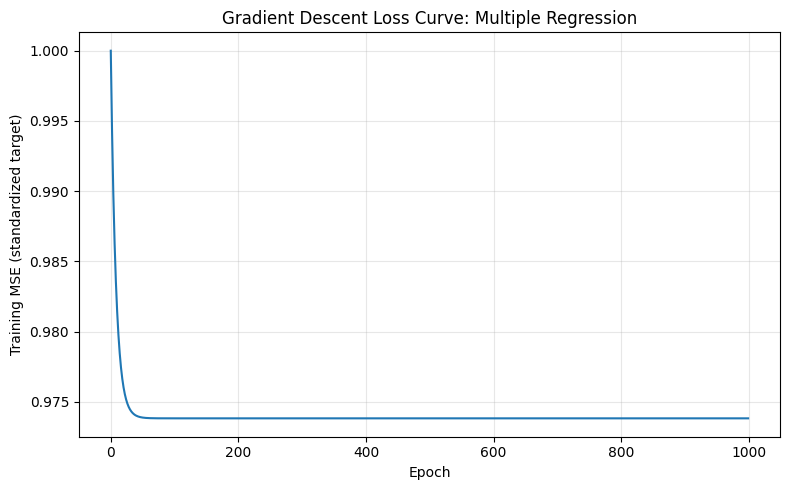

In [ ]:

# MULTIPLE LINEAR REGRESSION FROM SCRATCH
# Using Gradient Descent
# Evaluation: MSE and MAE only

# 1. Fill missing values using training-set medians
medians = X_train_m.median()

Xtr = X_train_m.fillna(medians).to_numpy(dtype=float)
Xte = X_test_m.fillna(medians).to_numpy(dtype=float)

# 2. Standardize input features
x_mean_m = Xtr.mean(axis=0)
x_std_m = Xtr.std(axis=0)
x_std_m[x_std_m == 0] = 1.0

Xtr_s = (Xtr - x_mean_m) / x_std_m
Xte_s = (Xte - x_mean_m) / x_std_m

# 3. Standardize target using training statistics
y_mean_m = y_train_m.mean()
y_std_m = y_train_m.std()

if y_std_m == 0:
    y_std_m = 1.0

ytr_s = (y_train_m.to_numpy() - y_mean_m) / y_std_m

# 4. Add intercept column
Xtr_bias = np.column_stack([
    np.ones(len(Xtr_s)), Xtr_s
])

Xte_bias = np.column_stack([
    np.ones(len(Xte_s)), Xte_s
])

# 5. Gradient Descent
theta = np.zeros(Xtr_bias.shape[1])

learning_rate = 0.03
epochs = 1000
loss_multi_history = []

for epoch in range(epochs):
    pred_train = Xtr_bias @ theta
    error = pred_train - ytr_s

    # Training MSE
    loss = np.mean(error ** 2)
    loss_multi_history.append(loss)

    # Calculate gradients
    gradient = (2 / len(ytr_s)) * (Xtr_bias.T @ error)

    # Update parameters
    theta -= learning_rate * gradient

# 6. Predict on test data
pred_multi_scratch = (
    Xte_bias @ theta
) * y_std_m + y_mean_m

# 7. Calculate MSE and MAE manually
test_errors = y_test_m.to_numpy() - pred_multi_scratch

mse_manual_multi = np.mean(test_errors ** 2)
mae_manual_multi = np.mean(np.abs(test_errors))

print("MULTIPLE LINEAR REGRESSION FROM SCRATCH")
print("-" * 45)
print(f"MSE: {mse_manual_multi:.6f}")
print(f"MAE: {mae_manual_multi:.6f}")

# 8. Plot the gradient descent loss curve
plt.figure(figsize=(8, 5))
plt.plot(loss_multi_history)
plt.xlabel("Epoch")
plt.ylabel("Training MSE (standardized target)")
plt.title("Gradient Descent Loss Curve: Multiple Regression")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


POLYNOMIAL REGRESSION: SCIKIT-LEARN
Degree: 2
MSE: 0.6448919710899909
MAE: 0.5669264785018983


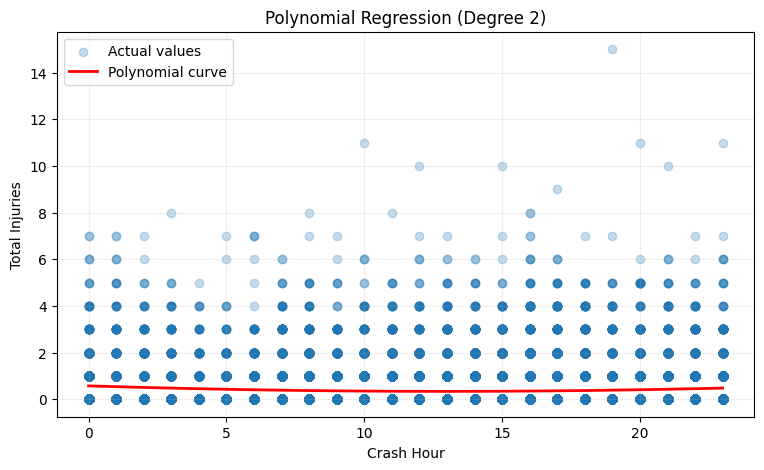

In [ ]:

# POLYNOMIAL REGRESSION USING SCIKIT-LEARN

poly_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

poly_model.fit(X_train_s, y_train_s)
pred_poly = poly_model.predict(X_test_s)

print("POLYNOMIAL REGRESSION: SCIKIT-LEARN")
print("Degree: 2")
print("MSE:", mean_squared_error(y_test_s, pred_poly))
print("MAE:", mean_absolute_error(y_test_s, pred_poly))

# Generate a smooth curve
x_curve = np.linspace(
    X_simple[:, 0].min(),
    X_simple[:, 0].max(),
    300
).reshape(-1, 1)

y_curve = poly_model.predict(x_curve)

plt.figure(figsize=(9, 5))
plt.scatter(
    X_test_s[:, 0], y_test_s,
    alpha=0.25, label="Actual values"
)
plt.plot(
    x_curve[:, 0], y_curve,
    color="red", linewidth=2, label="Polynomial curve"
)
plt.xlabel("Crash Hour")
plt.ylabel("Total Injuries")
plt.title("Polynomial Regression (Degree 2)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


POLYNOMIAL REGRESSION FROM SCRATCH
Intercept: 0.33651217172681847
Linear coefficient: 0.006689437945501489
Squared coefficient: 0.044111409685200074
MSE: 0.644891971089991
MAE: 0.5669264785018929


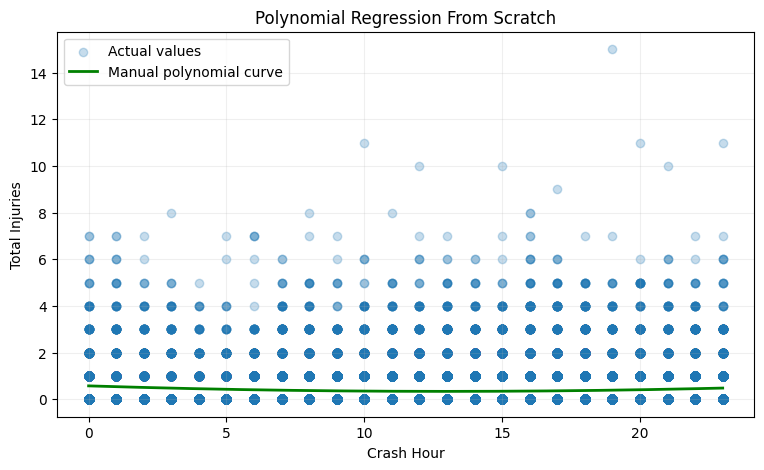

In [ ]:

# POLYNOMIAL REGRESSION FROM SCRATCH
# Degree 2: y = b0 + b1*x + b2*x^2

x_train = X_train_s[:, 0]
x_test = X_test_s[:, 0]

# Scale the predictor for numerical stability
x_mu = x_train.mean()
x_sd = x_train.std()
if x_sd == 0:
    x_sd = 1.0

x_train_scaled = (x_train - x_mu) / x_sd
x_test_scaled = (x_test - x_mu) / x_sd

# Construct polynomial design matrices manually
X_poly_train_manual = np.column_stack([
    np.ones(len(x_train_scaled)),
    x_train_scaled,
    x_train_scaled ** 2
])

X_poly_test_manual = np.column_stack([
    np.ones(len(x_test_scaled)),
    x_test_scaled,
    x_test_scaled ** 2
])

# Least-squares solution
beta_poly = np.linalg.lstsq(
    X_poly_train_manual, y_train_s, rcond=None
)[0]

pred_poly_manual = X_poly_test_manual @ beta_poly

print("POLYNOMIAL REGRESSION FROM SCRATCH")
print("Intercept:", beta_poly[0])
print("Linear coefficient:", beta_poly[1])
print("Squared coefficient:", beta_poly[2])
print("MSE:", np.mean((y_test_s - pred_poly_manual) ** 2))
print("MAE:", np.mean(np.abs(y_test_s - pred_poly_manual)))


# Graph
x_grid = np.linspace(x_train.min(), x_train.max(), 300)
x_grid_scaled = (x_grid - x_mu) / x_sd

X_grid_manual = np.column_stack([
    np.ones(len(x_grid)),
    x_grid_scaled,
    x_grid_scaled ** 2
])

y_grid_manual = X_grid_manual @ beta_poly

plt.figure(figsize=(9, 5))
plt.scatter(x_test, y_test_s, alpha=0.25, label="Actual values")
plt.plot(
    x_grid, y_grid_manual,
    color="green", linewidth=2, label="Manual polynomial curve"
)
plt.xlabel("Crash Hour")
plt.ylabel("Total Injuries")
plt.title("Polynomial Regression From Scratch")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


POLYNOMIAL REGRESSION: GRADIENT DESCENT
MSE: 0.6448919710899905
MAE: 0.5669264785019126


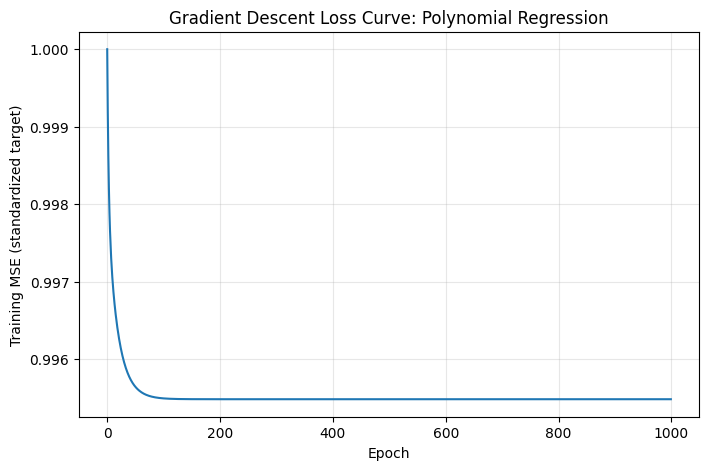

In [ ]:

# STANDARDIZE TARGET USING TRAINING DATA
y_mu_poly = y_train_s.mean()
y_sd_poly = y_train_s.std()
if y_sd_poly == 0:
    y_sd_poly = 1.0

y_train_poly_scaled = (y_train_s - y_mu_poly) / y_sd_poly

# Create design matrix using already standardized x
X_gd_poly = np.column_stack([
    np.ones(len(x_train_scaled)),
    x_train_scaled,
    x_train_scaled ** 2
])

theta_poly = np.zeros(X_gd_poly.shape[1])

learning_rate = 0.03
epochs = 1000
poly_loss_history = []

for epoch in range(epochs):
    pred = X_gd_poly @ theta_poly
    error = pred - y_train_poly_scaled

    loss = np.mean(error ** 2)
    poly_loss_history.append(loss)

    gradient = (2 / len(y_train_poly_scaled)) * (
        X_gd_poly.T @ error
    )

    theta_poly -= learning_rate * gradient

# Test predictions
X_test_gd_poly = np.column_stack([
    np.ones(len(x_test_scaled)),
    x_test_scaled,
    x_test_scaled ** 2
])

pred_poly_gd = (
    X_test_gd_poly @ theta_poly
) * y_sd_poly + y_mu_poly

print("POLYNOMIAL REGRESSION: GRADIENT DESCENT")
print("MSE:", mean_squared_error(y_test_s, pred_poly_gd))
print("MAE:", mean_absolute_error(y_test_s, pred_poly_gd))

# Loss curve
plt.figure(figsize=(8, 5))
plt.plot(poly_loss_history)
plt.xlabel("Epoch")
plt.ylabel("Training MSE (standardized target)")
plt.title("Gradient Descent Loss Curve: Polynomial Regression")
plt.grid(alpha=0.3)
plt.show()


Polynomial Regression Comparison


,Method,MSE,MAE
0,With Library,0.644892,0.566926
1,Without Library,0.644892,0.566926


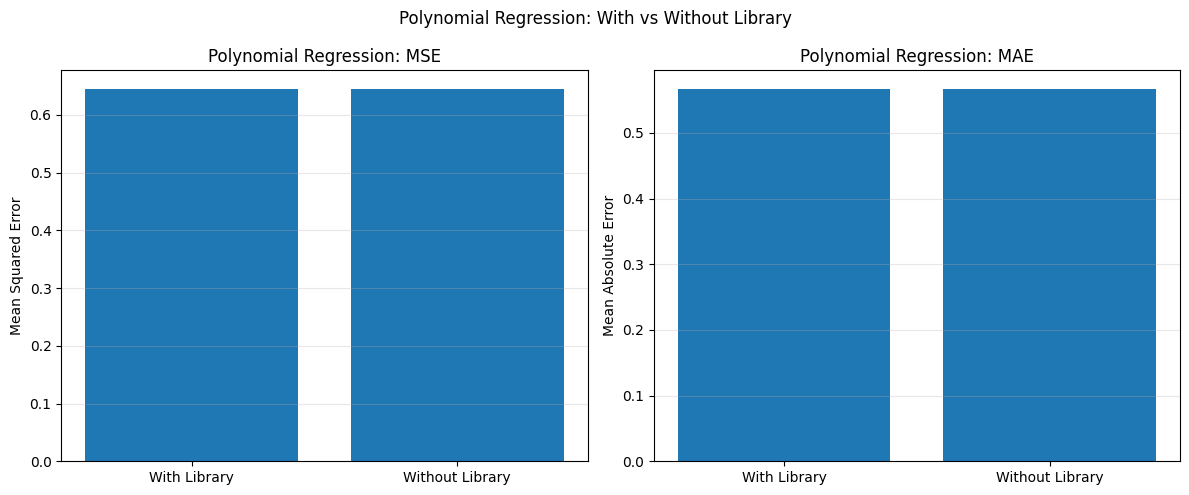

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Predictions using the existing sklearn polynomial model
pred_library_poly = poly_model.predict(X_test_s)

# Manual polynomial regression using x and x²
x_train_poly = X_train_s[:, 0]
x_test_poly = X_test_s[:, 0]

# Create polynomial feature matrices: [1, x, x²]
X_train_poly_manual = np.column_stack([
    np.ones(len(x_train_poly)),
    x_train_poly,
    x_train_poly ** 2
])

X_test_poly_manual = np.column_stack([
    np.ones(len(x_test_poly)),
    x_test_poly,
    x_test_poly ** 2
])

# Find coefficients using the least-squares solution
coefficients_poly = np.linalg.lstsq(
    X_train_poly_manual,
    np.asarray(y_train_s),
    rcond=None
)[0]

# Manual predictions
pred_without_library_poly = X_test_poly_manual @ coefficients_poly

# Calculate MSE and MAE
comparison_poly = pd.DataFrame({
    "Method": ["With Library", "Without Library"],
    "MSE": [
        np.mean((np.asarray(y_test_s) - pred_library_poly) ** 2),
        np.mean((np.asarray(y_test_s) - pred_without_library_poly) ** 2)
    ],
    "MAE": [
        np.mean(np.abs(np.asarray(y_test_s) - pred_library_poly)),
        np.mean(np.abs(np.asarray(y_test_s) - pred_without_library_poly))
    ]
})

print("Polynomial Regression Comparison")
display(comparison_poly.round(6))

# Plot bar graphs
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(comparison_poly["Method"], comparison_poly["MSE"])
axes[0].set_title("Polynomial Regression: MSE")
axes[0].set_ylabel("Mean Squared Error")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(comparison_poly["Method"], comparison_poly["MAE"])
axes[1].set_title("Polynomial Regression: MAE")
axes[1].set_ylabel("Mean Absolute Error")
axes[1].grid(axis="y", alpha=0.3)

plt.suptitle("Polynomial Regression: With vs Without Library")
plt.tight_layout()
plt.show()

FINAL REGRESSION COMPARISON


,Model,MSE,MAE
0,Simple Linear,0.6478,0.5693
1,Multiple Linear,0.6308,0.5578
2,Polynomial Degree 2,0.6449,0.5669


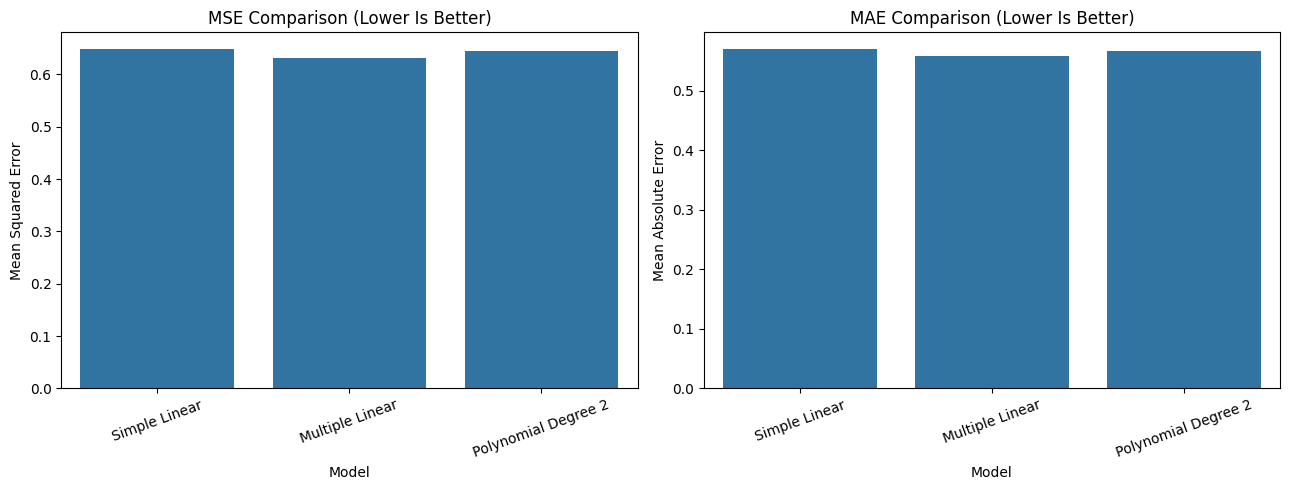

In [ ]:

all_results = pd.DataFrame([
    {
        "Model": "Simple Linear",
        "MSE": mean_squared_error(y_test_s, pred_linear),
        "MAE": mean_absolute_error(y_test_s, pred_linear)
    },
    {
        "Model": "Multiple Linear",
        "MSE": mean_squared_error(y_test_m, pred_multiple),
        "MAE": mean_absolute_error(y_test_m, pred_multiple)
    },
    {
        "Model": "Polynomial Degree 2",
        "MSE": mean_squared_error(y_test_s, pred_poly),
        "MAE": mean_absolute_error(y_test_s, pred_poly)
    }
])

print("FINAL REGRESSION COMPARISON")
display(all_results.round(4))

# Plot only MSE and MAE
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(data=all_results, x="Model", y="MSE", ax=axes[0])
axes[0].set_title("MSE Comparison (Lower Is Better)")
axes[0].set_ylabel("Mean Squared Error")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=all_results, x="Model", y="MAE", ax=axes[1])
axes[1].set_title("MAE Comparison (Lower Is Better)")
axes[1].set_ylabel("Mean Absolute Error")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


In [ ]:


models = {
    "Multiple Linear Regression": LinearRegression(),
    "Lasso Regression": Lasso(alpha=0.1, max_iter=10000),
    "Ridge Regression": Ridge(alpha=1.0),
    "Elastic Net Regression": ElasticNet(
        alpha=0.1, l1_ratio=0.5, max_iter=10000
    )
}

results = []

for name, model in models.items():
    pipeline = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        model
    )

    pipeline.fit(X_train_m, y_train_m)
    predictions = pipeline.predict(X_test_m)

    results.append({
        "Model": name,
        "MSE": mean_squared_error(y_test_m, predictions),
        "MAE": mean_absolute_error(y_test_m, predictions)
    })

results_df = pd.DataFrame(results)
display(results_df.sort_values("MAE").round(4))

,Model,MSE,MAE
0,Multiple Linear Regression,0.6308,0.5578
2,Ridge Regression,0.6308,0.5578
3,Elastic Net Regression,0.6343,0.5626
1,Lasso Regression,0.6416,0.5669


**Result :** The regression models were studied and implemented using the traffic accident dataset to predict the total number of injuries (injuries_total). The dataset was preprocessed, relevant input features were selected, and the data was divided into training and testing sets.
Simple Linear Regression was used to analyze the relationship between a single feature and total injuries. Multiple Linear Regression considered multiple input features, while Polynomial Regression was used to capture possible nonlinear relationships. Locally Weighted Linear Regression was studied to understand how local data points can influence predictions. Gradient Descent was applied to update model parameters iteratively, and its learning process was analyzed using loss curves and theta-versus-iterations graphs.
The performance of the regression models was evaluated using Mean Squared Error (MSE) and Mean Absolute Error (MAE). These metrics help measure prediction errors and compare model performance. The model with lower test-set MSE and MAE generally provides more accurate predictions on the evaluated data.
Thus, the assignment demonstrated the working principles of regression techniques, parameter optimization, error analysis, and graphical visualization of model performance.






**Conclusion :**
1. Strengths and weaknesses of each model


Model 1: Simple Linear Regression (SLR)
One input feature


Uses crash_hour to predict injuries_total.
Strengths
- Simple to understand and implement.
- Fast to train and predict.
- Easy to interpret the relationship between crash hour and injuries.
- Useful as a baseline for comparing other models.


Weaknesses
- Uses only one feature, ignoring other factors such as the number of vehicles involved.
- Assumes a straight-line relationship between crash hour and injuries.
- May underfit if the relationship is more complex.
- Cannot explain all the factors contributing to injuries.


Model 2: Multiple Linear Regression (MLR)


Multiple input features
Uses available features such as crash_hour, num_units, crash_day_of_week, crash_month, and crash_year.
Strengths
- Considers multiple variables simultaneously.
- Can capture relationships that a single-feature model misses.
- Coefficients help explain how the selected features relate to predicted injuries.
- Often provides a stronger baseline when additional features contain useful information.


Weaknesses
- Assumes a linear relationship between features and the target.
- Irrelevant or redundant features can reduce predictive usefulness.
- Raw numerical encodings of categorical variables can be misleading.
- More features do not automatically guarantee lower test error.


Model 3: Polynomial Regression


Nonlinear relationship
Your degree-2 model uses crash_hour and its squared term, \(x^2\).
Strengths
- Can model curved relationships.
- Captures patterns that ordinary linear regression may miss.
- Degree 2 is relatively simple compared with higher-degree polynomials.


Weaknesses
- Can overfit if unnecessary polynomial terms are added.
- May predict unrealistic values outside the observed range.
- A quadratic curve may not represent the true relationship.
- Using only crash_hour still ignores other potentially important variables.


Model 4: Gradient Descent


Optimization method
Gradient descent is a method for learning model parameters, such as theta values. In your assignment, it is used to train regression models manually.
Strengths
- Helps understand how a model learns its parameters.
- Can handle large datasets when implemented efficiently.
- The learning process can be studied using the error-reduction graph.
- Can be used for both simple and multiple regression.


Weaknesses
- Performance depends on the learning rate.
- Too many or too few iterations can cause problems.
- Incorrect scaling or gradient calculations can lead to unstable training.
- May converge slowly or fail to converge with unsuitable settings.
Important: Gradient descent is not a separate regression model by itself. It is an optimization algorithm. Compare it against the library implementation of the same regression model to assess how well your manual implementation works.


Model 5: Locally Weighted Linear Regression (LWLR)


Local predictions
LWLR gives more weight to training observations near the point being predicted and less weight to distant observations.


Strengths
- Can capture local patterns that a single global line misses.
- Does not require one fixed relationship to fit the entire dataset.
- Useful when the relationship between crash hour and injuries changes across different hours.


Weaknesses
- Computationally expensive because it calculates local weights for predictions.
- Sensitive to the bandwidth parameter.
- Can perform poorly when few nearby observations are available.
- May be impractical for very large datasets without optimization.


**Outcomes :**
1. Understood the fundamentals of regression analysis and its application to traffic accident data.
2. Learned to preprocess the dataset, select relevant features, and divide the data into training and testing sets.
3. Implemented Simple Linear Regression to study the relationship between a single input feature and total injuries.
4. Applied Multiple Linear Regression to predict total injuries using multiple input features.
5. Studied Polynomial Regression to model nonlinear relationships using polynomial features.
6. Understood Locally Weighted Linear Regression and how local data points influence predictions.
7. Implemented Gradient Descent to optimize regression parameters and studied theta updates over successive iterations.
8. Visualized error reduction using loss curves and analyzed parameter convergence through theta-versus-iterations graphs.
9. Evaluated regression performance using Mean Squared Error (MSE) and Mean Absolute Error (MAE).
10. Compared the strengths and limitations of regression techniques and understood that model performance depends on the dataset, selected features, and evaluation results.
11. Developed practical experience in using Python, NumPy, Pandas, Matplotlib, and Scikit-learn for regression analysis and visualization.